# 01 · Preprocessing — Tirosh 2016 melanoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap** (median-restricted, so the dominant sample and the sequencing-spillover tail
do not distort the cut), integrate patients (Harmony), embed, and remove detached
islands. Unlike Kürten 2021 — whose malignant manifold splits into two
transcriptional lobes — Tirosh's melanoma cells form **one continuous
MITF-high melanocytic compartment**, so no compartment split is applied: the
whole manifold carries the embryonic gradient into 02.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Tirosh2016_Skin | category: Skin


### Load malignant compartment
Tirosh et al. annotate cell type directly (SmartSeq2, TPM); we take their
`Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Tirosh2016_Skin
Done.
full atlas: (4645, 23686)
malignant: (1257, 23686) | samples: 15


### Sample thresholding — derived by median-restricted multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude, dominated by one large
lesion (468 cells) with a long tail of tumours contributing only a handful of
spillover cells. A naive largest-multiplicative-gap cut lands in that noisy tail;
we therefore **restrict** the search to interior gaps whose two sides each hold
≥10 % of the largest sample (excluding both the singleton-dominant top gap and the
sub-threshold tail), then cut at the geometric mean of the widest remaining gap.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
floor = 0.10 * vals.max()
valid = [i for i in range(len(ratios)) if i >= 1 and vals[i] >= floor and vals[i+1] >= floor]
gap = max(valid, key=lambda i: ratios[i])
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'median-restricted largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [468, 133, 125, 120, 117, 98, 54, 54, 32, 16, 14, 10, 9, 4, 3]
median-restricted largest gap: 98 -> 54 (ratio 1.81)
derived threshold (geometric mean across the gap) = 72
kept 6/15 samples -> 1061 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta=2` (light patient correction — melanoma malignant programs are strongly
patient-private, so aggressive mixing would erase real biology) and `n_pcs=20`
(matching the reference-study scale; the manifold topology is invariant across
n_pcs 8–20, so the precedent value is used).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=2, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.0, min_dist=0.5, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2753 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2753
2026-07-30 18:43:09,949 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-30 18:43:10,222 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-30 18:43:10,228 - harmonypy - INFO - Iteration 1 of 30
2026-07-30 18:43:10,442 - harmonypy - INFO - Iteration 2 of 30
2026-07-30 18:43:10,655 - harmonypy - INFO - Iteration 3 of 30
2026-07-30 18:43:10,868 - harmonypy - INFO - Iteration 4 of 30
2026-07-30 18:43:11,081 - harmonypy - INFO - Iteration 5 of 30
2026-07-30 18:43:11,245 - harmonypy - INFO - Converged after 5 iterations


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and
drop any cell outside the main connected component — stripping physically
detached specks while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Subtype annotation (data markers + published 3CA meta-programs)
Low-resolution Leiden (res=0.3) recovers the melanocytic substructure. Following
the standing rule that annotation uses **both** data-derived markers and the
publication's reported programs, each cluster is labelled by its marker profile
(proliferation, pigmentation, AP1-stress) cross-referenced against the dominant
Curated Cancer Cell Atlas (3CA) meta-program (`mp_top`). Every cluster is
MITF/MLANA/PMEL-high → **one continuous melanocytic compartment** (no lobe split;
biology leads geometry for Gate 1).

In [7]:
sc.tl.leiden(adata, resolution=0.3, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
def _sig(genes):
    gg=[g for g in genes if g in adata.var_names]
    return np.asarray(adata[:,gg].X.mean(1)).ravel()
prog = {'MITF':['MITF','MLANA','PMEL','TYR','DCT','TYRP1'],
        'Pigment':['PMEL','TYR','TYRP1','DCT'],
        'AP1':['FOS','JUN','JUNB','FOSB'],
        'CellCycle':['MKI67','TOP2A','CENPF','CCNB1']}
for k,gs in prog.items(): adata.obs['p_'+k]=_sig(gs)
prof = adata.obs.groupby('leiden',observed=True)[['p_'+k for k in prog]].mean().round(2)
print('marker programs per cluster:'); print(prof.to_string())
mp = pd.crosstab(adata.obs['leiden'], adata.obs['mp_top'], normalize='index')
for cl in adata.obs.leiden.cat.categories:
    top = mp.loc[cl].sort_values(ascending=False).head(3)
    print(f'cluster {cl} (n={int((adata.obs.leiden==cl).sum())}) top 3CA MPs:',
          {k: round(v,2) for k,v in top.items()})
# label by biology (marker profile anchored in the dominant 3CA program)
cc = adata.obs.groupby('leiden',observed=True)['p_CellCycle'].mean()
ap = adata.obs.groupby('leiden',observed=True)['p_AP1'].mean()
cyc_cl = cc.idxmax(); stress_cl = ap.drop(cyc_cl).idxmax()
sub_map = {}
for cl in adata.obs.leiden.cat.categories:
    if cl==cyc_cl: sub_map[cl]='Cycling/Hypoxic'
    elif cl==stress_cl: sub_map[cl]='Pigmented-Stress'
    else: sub_map[cl]='Melanocytic-quiescent'
adata.obs['subtype'] = adata.obs['leiden'].map(sub_map).astype('category')
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())
print('all clusters MITF-high (mean %.2f) -> single melanocytic compartment'
      % adata.obs['p_MITF'].mean())

marker programs per cluster:
        p_MITF  p_Pigment  p_AP1  p_CellCycle
leiden                                       
0         4.78       4.63   4.36         0.93
1         4.50       4.31   3.96         0.22
2         4.51       4.11   5.88         0.13
cluster 0 (n=400) top 3CA MPs: {'Hypoxia': 0.19, 'Cell Cycle - G1/S': 0.15, 'Interferon/MHC-II (I)': 0.09}
cluster 1 (n=436) top 3CA MPs: {'Skin pigmentation': 0.16, 'Stress': 0.14, 'Interferon/MHC-II (I)': 0.1}
cluster 2 (n=225) top 3CA MPs: {'Stress': 0.36, 'Interferon/MHC-II (I)': 0.15, 'Skin pigmentation': 0.11}
subtypes: {'Melanocytic-quiescent': 436, 'Cycling/Hypoxic': 400, 'Pigmented-Stress': 225}
all clusters MITF-high (mean 4.61) -> single melanocytic compartment


### Gate 1 — batch mixing & manifold continuity
Malignant cells from multiple patients must intermix on one continuous manifold
(no per-patient islands). Visual inspection below; the deliverable `samples.pdf`
follows.

6 samples on one continuous manifold; mean cross-sample kNN fraction = 0.47
Gate 1: multi-patient intermixing on one continuous manifold -> GO


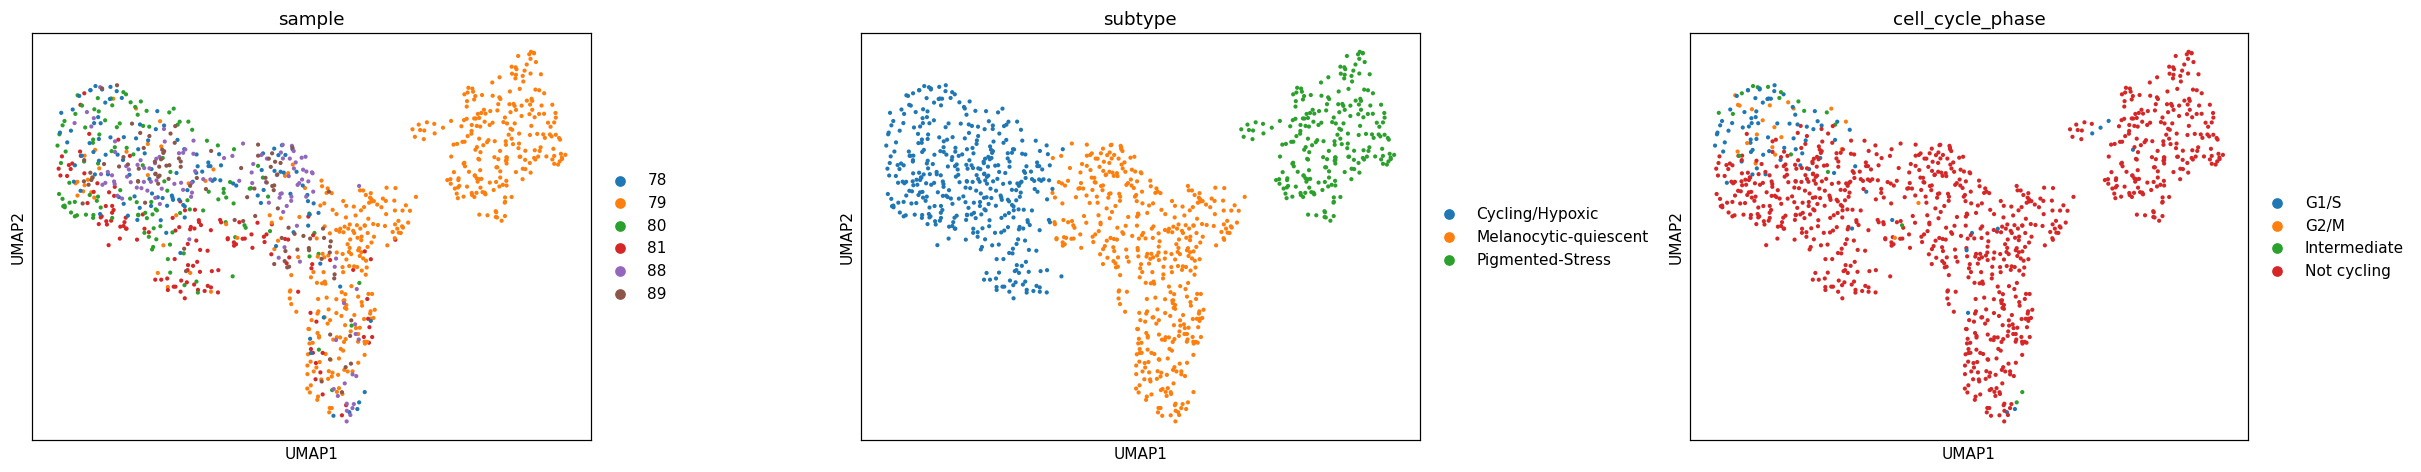

In [8]:
fig = sc.pl.umap(adata, color=['sample','subtype','cell_cycle_phase'],
                 size=30, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
# quantify mixing: mean fraction of a cell's kNN drawn from other samples
from sklearn.neighbors import NearestNeighbors as _NN
kk = _NN(n_neighbors=16).fit(adata.obsm['X_umap']).kneighbors(adata.obsm['X_umap'], return_distance=False)[:,1:]
s = adata.obs['sample'].values
mix = np.mean([ (s[kk[i]] != s[i]).mean() for i in range(adata.n_obs) ])
print(f'{n_samp} samples on one continuous manifold; mean cross-sample kNN fraction = {mix:.2f}')
print('Gate 1: multi-patient intermixing on one continuous manifold -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1061, 19950)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample.
The whole malignant manifold is shown (Tirosh has a single compartment). Cross-sample
intermixing across the strip is the Gate-1 batch-integration evidence; orientation
is not pseudotime-signed here (that axis is fixed in 02_manifold), so a plain x-flip
places the eventual root at the left — direction is immaterial for this categorical
panel.

saved samples.pdf | malignant cells: 1061


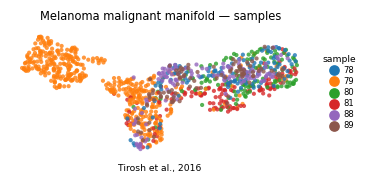

In [10]:
traj = adata.copy()
xy = traj.obsm['X_umap'].astype(float)
traj.obsm['X_umap'] = np.column_stack([-xy[:,0], xy[:,1]])   # x-flip (major axis already horizontal)
xl = traj.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(traj, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | malignant cells:', traj.shape[0])